In [1]:
%pip install --upgrade --force-reinstall torch torchvision --index-url https://download.pytorch.org/whl/cu126 --timeout 1000 --retries 10
%pip install -q pandas matplotlib scikit-learn Pillow segmentation-models-pytorch


^C
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Looking in indexes: https://download.pytorch.org/whl/cu126
  Using cached https://download-r2.pytorch.org/whl/cu126/torch-2.14.1%2Bcu126-cp312-cp312-win_amd64.whl.metadata (37 kB)
  Using cached https://download-r2.pytorch.org/whl/cu126/torchvision-0.29.1%2Bcu126-cp312-cp312-win_amd64.whl.metadata (5.8 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached https://download.pytorch.org/whl/setuptools-78.1.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached https://download.pytorch.org/whl/jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached pillow-13.0.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached mpmath

## 1. Setup – Mount Google Drive and Configure Paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

PROJECT_ROOT = '/content/drive/MyDrive/Binary Image Segmentation'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.chdir(PROJECT_ROOT)
print(f"Working directory: {os.getcwd()}")


## 2. Environment Check

In [2]:
import sys, torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")


Python: c:\Users\adith\AppData\Local\Programs\Python\Python312\python.exe
PyTorch: 2.14.1+cu126
CUDA build: 12.6
CUDA available: True
Training on: cuda


## 3. Configuration

In [3]:
from src.config import (
    IMAGE_DIR, MASK_DIR, CHECKPOINT_DIR, OUTPUT_DIR,
    IMG_SIZE, BATCH_SIZE, VAL_BATCH,
    IMAGENET_MEAN, IMAGENET_STD,
    UNET_EPOCHS, FPN_EPOCHS, SAM2_EPOCHS, FCN_EPOCHS,
    EARLY_STOP_PATIENCE, LEARNING_RATE,
    UNET_CKPT, FPN_CKPT, SAM2_CKPT, FCN_CKPT,
)

print("Image directory :", IMAGE_DIR)
print("Mask  directory :", MASK_DIR)
print("Checkpoint dir  :", CHECKPOINT_DIR)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Config loaded successfully.")


Image directory : C:\Projects\Binary Image Segmentation\grayscaleImages\images
Mask  directory : C:\Projects\Binary Image Segmentation\grayscaleImages\masks
Checkpoint dir  : C:\Projects\Binary Image Segmentation\checkpoints
Config loaded successfully.


## 4. Data Loading

In [4]:
import pandas as pd
from src.dataset import build_dataframes, build_dataloaders

df, train_df, val_df, test_df = build_dataframes()

print(f"Total image-mask pairs : {len(df)}")
print(f"Training Set           : {len(train_df)} ({len(train_df)/len(df)*100:.0f}%)")
print(f"Validation Set         : {len(val_df)}  ({len(val_df)/len(df)*100:.0f}%)")
print(f"Testing Set            : {len(test_df)}  ({len(test_df)/len(df)*100:.0f}%)")
df.head()


Total image-mask pairs : 1000
Training Set           : 700 (70%)
Validation Set         : 150  (15%)
Testing Set            : 150  (15%)


,image_path,mask_path,file_name
0,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_001.jpg
1,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_002.jpg
2,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_003.jpg
3,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_004.jpg
4,C:\Projects\Binary Image Segmentation\grayscal...,C:\Projects\Binary Image Segmentation\grayscal...,000002_005.jpg


### 4.1 Exploratory Data Visualisation

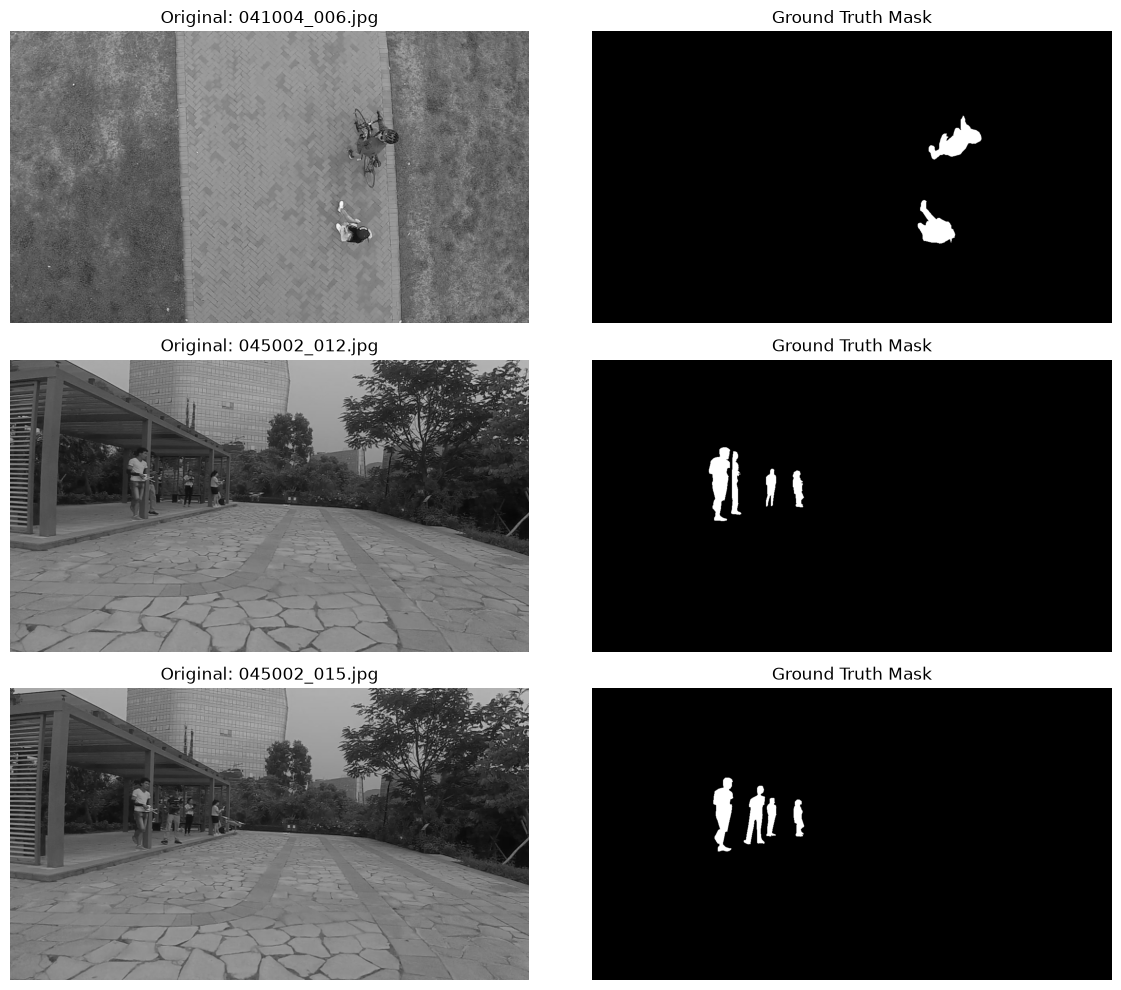

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

sample_rows = df.sample(3, random_state=42).reset_index(drop=True)
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for idx, row in sample_rows.iterrows():
    img = Image.open(row["image_path"]).convert("RGB")
    mask = Image.open(row["mask_path"]).convert("L")
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Original: {row['file_name']}")
    axes[idx, 0].axis("off")
    axes[idx, 1].imshow(mask, cmap='gray')
    axes[idx, 1].set_title("Ground Truth Mask")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()


### 4.2 Label Mapping

 Class ID Label Name  Raw Mask Value Visual Color
        0 Background               0        Black
        1     Person             255        White


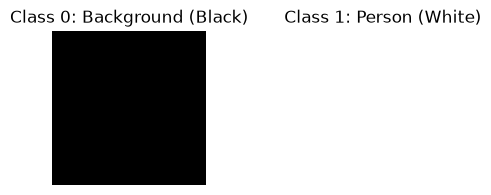

In [6]:
mapping_df = pd.DataFrame([
    {"Class ID": 0, "Label Name": "Background", "Raw Mask Value": 0,   "Visual Color": "Black"},
    {"Class ID": 1, "Label Name": "Person",     "Raw Mask Value": 255, "Visual Color": "White"},
])
print(mapping_df.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(6, 2))
ax[0].imshow(np.zeros((60, 60, 3), dtype=np.uint8))
ax[0].set_title("Class 0: Background (Black)")
ax[0].axis("off")
ax[1].imshow(np.ones((60, 60, 3), dtype=np.uint8) * 255)
ax[1].set_title("Class 1: Person (White)")
ax[1].axis("off")
plt.show()


### 4.3 Build DataLoaders

In [7]:
import torch

(
    train_dataset, val_dataset, test_dataset,
    train_loader,  val_loader,  test_loader,
) = build_dataloaders(train_df, val_df, test_df)

sample_img, sample_mask = train_dataset[0]
print(f"Input Image Tensor shape : {sample_img.shape}")
print(f"Target Mask Tensor shape : {sample_mask.shape}")
print(f"Unique classes in mask   : {torch.unique(sample_mask).tolist()}")
print(f"Batches  Train={len(train_loader)} | Val={len(val_loader)} | Test={len(test_loader)}")


Input Image Tensor shape : torch.Size([3, 256, 256])
Target Mask Tensor shape : torch.Size([256, 256])
Unique classes in mask   : [0, 1]
Batches  Train=44 | Val=5 | Test=5


## 5. MobileNetV3-UNet

In [ ]:
from src.models    import build_mobileunet
from src.trainer   import train_model, plot_training_curves, compute_pos_weight
from src.metrics   import evaluate_model, print_eval_report
from src.visualise import visualise_predictions
import torch.nn as nn

model = build_mobileunet(device)


### 5.1 Train

In [ ]:
model, unet_history = train_model(
    model         = model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = UNET_EPOCHS,
    model_name    = "MobileNetV3-UNet",
    save_path     = str(UNET_CKPT),
)


### 5.2 Training Curves

In [ ]:
plot_training_curves(unet_history, model_name="MobileNetV3-UNet")


### 5.3 Evaluate

In [ ]:
unet_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
unet_metrics = evaluate_model(
    model        = model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = unet_criterion,
    device       = device,
)
print_eval_report(unet_metrics, model_name="MobileNetV3-UNet")


### 5.4 Inference Visualisation

In [ ]:
visualise_predictions(model, test_dataset, device, model_name="MobileNetV3-UNet")


## 6. Feature Pyramid Network (FPN)

In [ ]:
from src.models import build_fpn

fpn_model = build_fpn(device)


### 6.1 Train

In [ ]:
fpn_model, fpn_history = train_model(
    model         = fpn_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = FPN_EPOCHS,
    model_name    = "FPN",
    save_path     = str(FPN_CKPT),
)


### 6.2 Training Curves

In [ ]:
plot_training_curves(fpn_history, model_name="FPN")


### 6.3 Evaluate

In [ ]:
fpn_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
fpn_metrics = evaluate_model(
    model        = fpn_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = fpn_criterion,
    device       = device,
)
print_eval_report(fpn_metrics, model_name="FPN")
visualise_predictions(fpn_model, test_dataset, device, model_name="FPN")


## 7. SAM 2 Segmentation Model

In [ ]:
from src.models import build_sam2

sam2_model = build_sam2(device)


### 7.1 Train

In [ ]:
sam2_model, sam2_history = train_model(
    model         = sam2_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = SAM2_EPOCHS,
    model_name    = "SAM 2",
    save_path     = str(SAM2_CKPT),
)


### 7.2 Training Curves

In [ ]:
plot_training_curves(sam2_history, model_name="SAM 2")


### 7.3 Evaluate

In [ ]:
sam2_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
sam2_metrics = evaluate_model(
    model        = sam2_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = sam2_criterion,
    device       = device,
)
print_eval_report(sam2_metrics, model_name="SAM 2")
visualise_predictions(sam2_model, test_dataset, device, model_name="SAM 2")


## 8. FCN (ResNet50)

In [ ]:
from src.models import build_fcn

fcn_model = build_fcn(device)


### 8.1 Train

In [ ]:
fcn_model, fcn_history = train_model(
    model         = fcn_model,
    train_loader  = train_loader,
    val_loader    = val_loader,
    train_dataset = train_dataset,
    device        = device,
    num_epochs    = FCN_EPOCHS,
    model_name    = "FCN",
    save_path     = str(FCN_CKPT),
)


### 8.2 Training Curves

In [ ]:
plot_training_curves(fcn_history, model_name="FCN (ResNet50)")


### 8.3 Evaluate

In [ ]:
fcn_criterion = nn.BCEWithLogitsLoss(
    pos_weight=compute_pos_weight(train_dataset, device)
)
fcn_metrics = evaluate_model(
    model        = fcn_model,
    test_loader  = test_loader,
    test_dataset = test_dataset,
    criterion    = fcn_criterion,
    device       = device,
)
print_eval_report(fcn_metrics, model_name="FCN (ResNet50)")
visualise_predictions(fcn_model, test_dataset, device, model_name="FCN")


## 9. Comprehensive Model Benchmark Comparison

In [ ]:
from src.visualise import plot_benchmark_comparison

all_metrics = {
    "MobileNetV3-UNet": unet_metrics,
    "FPN (ResNet34)":   fpn_metrics,
    "SAM 2":            sam2_metrics,
    "FCN (ResNet50)":   fcn_metrics,
}

comparison_df = plot_benchmark_comparison(all_metrics)
comparison_df
